# Numerical example
This notebook reproduces the figures of the numerical example in the paper. CASSPAR is compared with linear regression (LR) and DirectLiNGAM applied to `[X, y]` (LiNGAM).

## Import and settings

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

import plotting
from aggregate import METRICS, aggregate
from monte_carlo import PAPER_GRID, QUICK_GRID, load_results, run_monte_carlo
from run_one import run_one
from simulation import SimulationConfig, W_TYPES

plotting.use_paper_style()

## Settings
Data are generated on a grid of P locations for T samples:
$y_t = (I - \rho W)^{-1}(X_t \beta + \varepsilon_t)$, where each row of $X_t$ (K=3 covariates) follows a LiNGAM with a random DAG and $\varepsilon_t \sim U(-1, 1)$. $\beta \sim N(0, 10^2)$ is drawn for each seed.

| Parameter | Values |
|---|---|
| Spatial structure $W$ | Type 1 (spread from center), Type 2 (flow from left to right), Type 3 (queen adjacency) |
| P | 9, 25, 49, 81 |
| T | 200, 400, 600, 800, 1000, 1500, 2000 |
| $\rho$ | 0.7 |
| Seeds | 200 |

X and y are standardized, and 80% of the samples are used for training. $\beta$ is evaluated on the original scale, and the prediction of y on the test data.

In [2]:
SimulationConfig()

SimulationConfig(grid_size=7, T=1000, K=3, W_type='point', rho=0.7, edge_prob=0.2, weight_min=-1.0, weight_max=1.0, x_noise_scale=1.0, noise_eps=1.0, range_dist=100, peak_idx=0, burn_in=50)

## Single run
One run with T=1000 and P=49 for each spatial structure (Fig. 4 and 5 in the paper).

In [3]:
runs = {w: run_one(W_type=w, P=49, T=1000, seed=None, return_arrays=True) for w in W_TYPES}
W_true = {w: r['W_true'] for w, r in runs.items()}
W_hat = {w: r['W_hat'] for w, r in runs.items()}

True $W$ (arrows and heatmap):

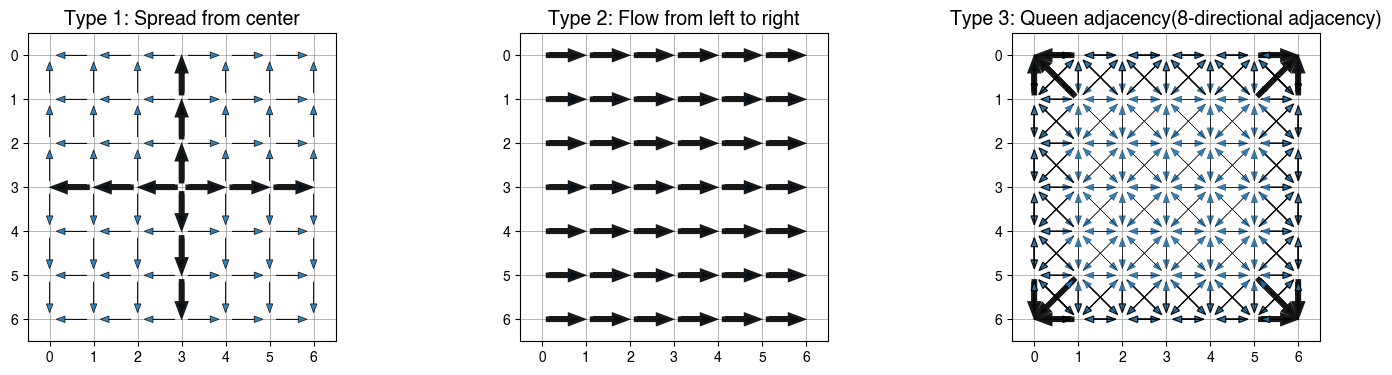

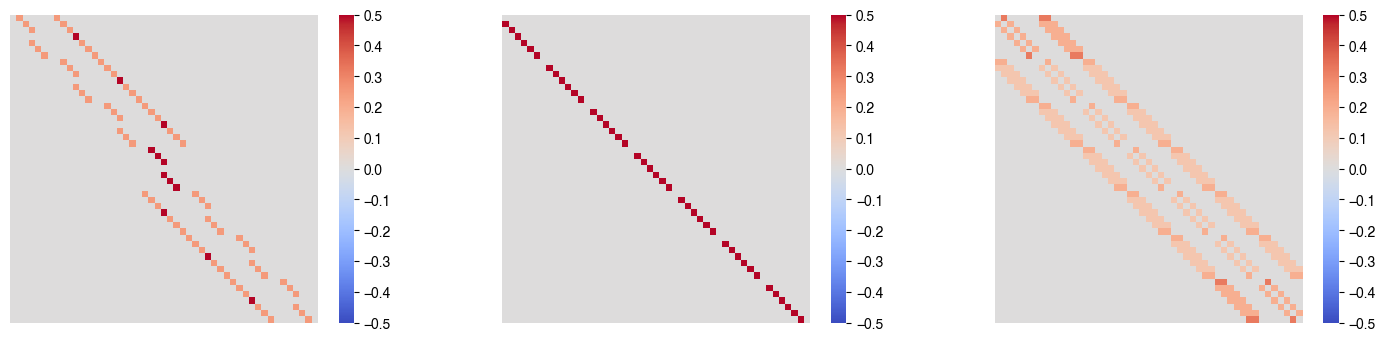

In [4]:
plotting.plot_W_types(W_true, kind='arrows', titles=True)
plt.show()
plotting.plot_W_types(W_true)
plt.show()

$W$ estimated by CASSPAR:

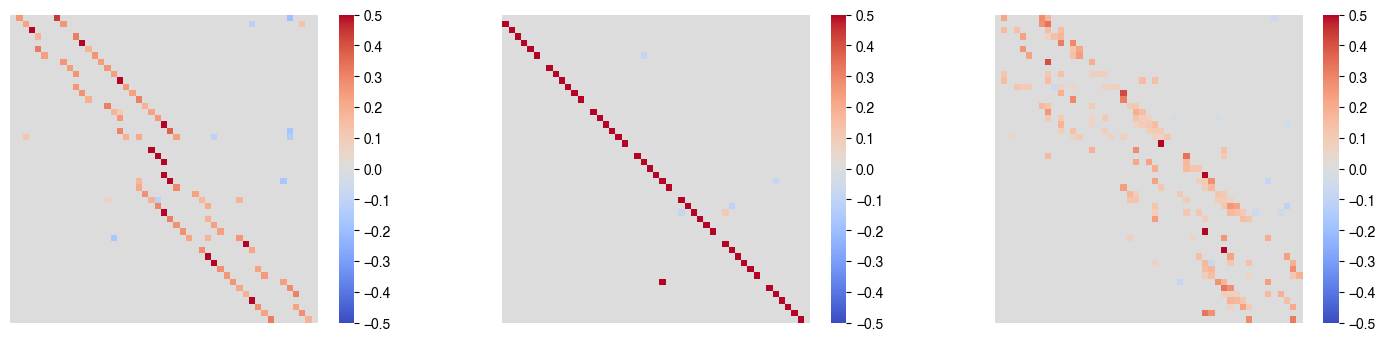

In [5]:
plotting.plot_W_types(W_hat)
plt.show()

## Monte Carlo results
Median (line) and interquartile range (band) of the MAE over 200 seeds, read from the bundled CSV files (`data/`, P=9, 25, 49 as in the paper).

In [6]:
mae_beta = pd.read_csv('data/mae_beta.csv')
mae_W = pd.read_csv('data/mae_W.csv')
mae_y = pd.read_csv('data/mae_y.csv')
mae_beta.head()

,P,type,T,method,n_seed,mean,std,median,q25,q75
0,9,Type 1,200,CASSPAR,195,0.136385,0.084397,0.115889,0.076771,0.175771
1,9,Type 1,400,CASSPAR,200,0.088152,0.060211,0.076849,0.042473,0.122444
2,9,Type 1,600,CASSPAR,200,0.067386,0.055264,0.050544,0.023088,0.102391
3,9,Type 1,800,CASSPAR,200,0.057793,0.056742,0.038062,0.018182,0.076287
4,9,Type 1,1000,CASSPAR,200,0.049763,0.051946,0.026920,0.013696,0.067812


MAE of $\beta$:

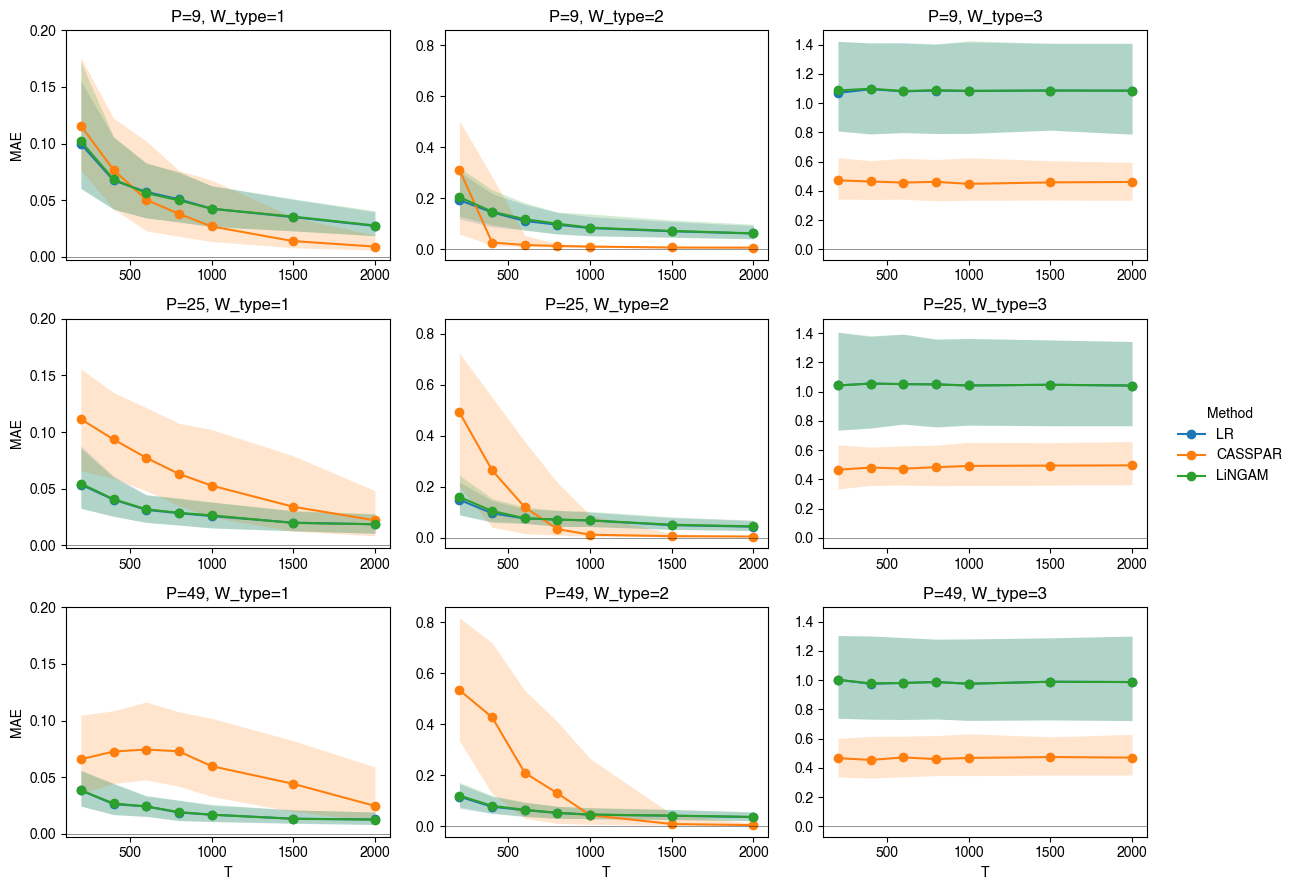

In [7]:
plotting.plot_mae(mae_beta, methods=['LR', 'CASSPAR', 'LiNGAM'], ymax={'Type 1': 0.2})
plt.show()

MAE of $W$ (off-diagonal elements):

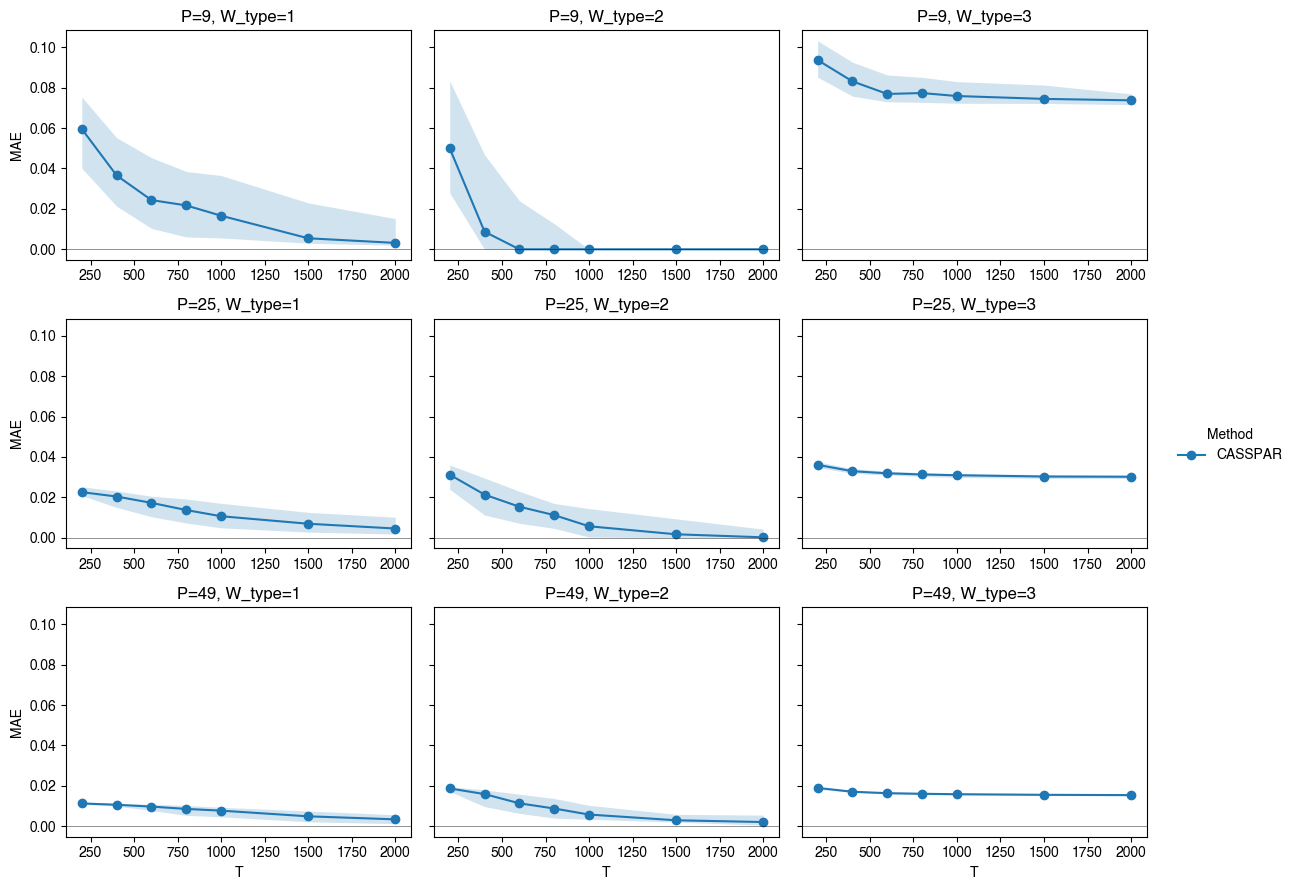

In [8]:
plotting.plot_mae(mae_W, sharey=True)
plt.show()

MAE of the prediction of y (test data, standardized scale):

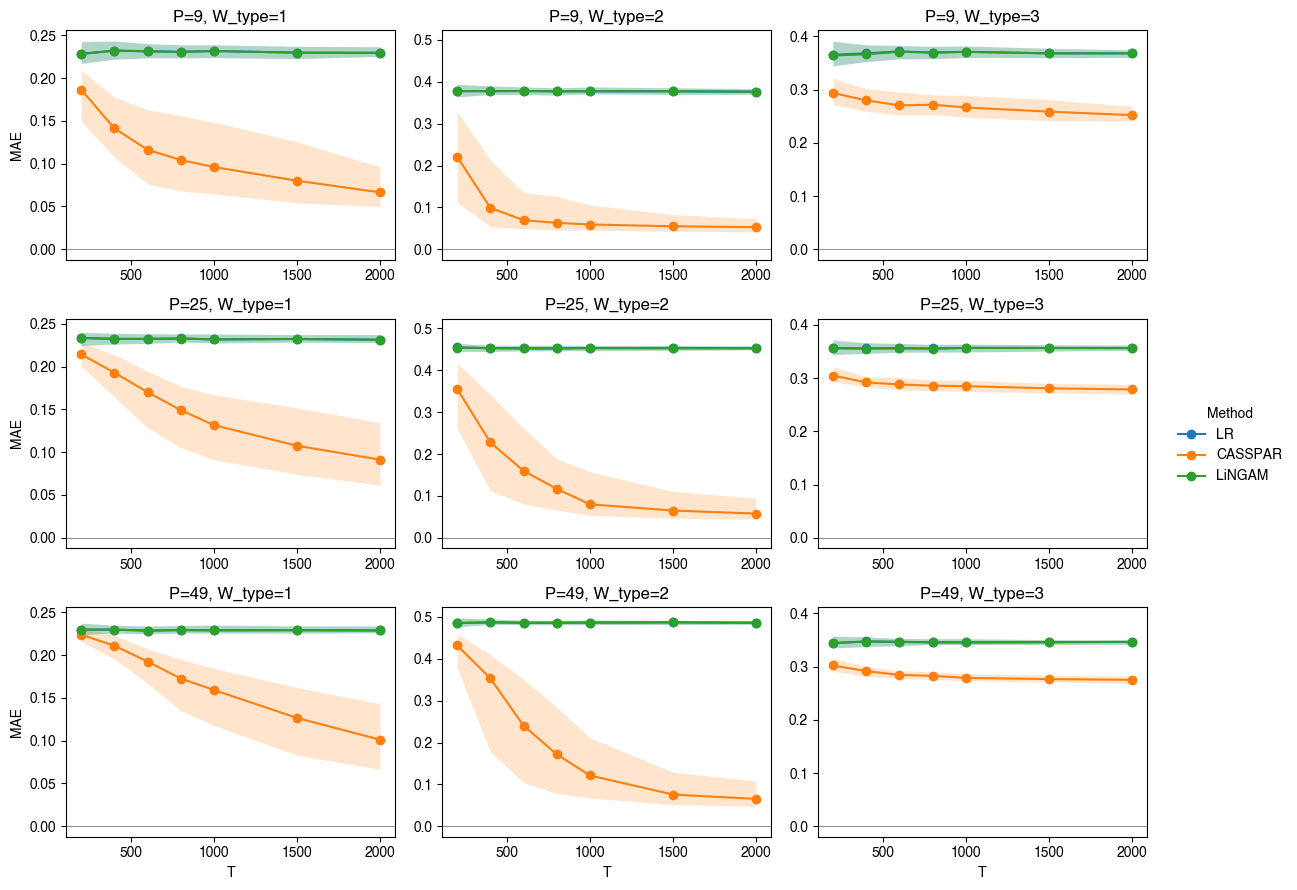

In [9]:
plotting.plot_mae(mae_y, methods=['LR', 'CASSPAR', 'LiNGAM'])
plt.show()

## Re-running the simulation
The full grid (`PAPER_GRID`, 16,800 runs) takes long. `QUICK_GRID` checks the pipeline in a minute. Set `RUN_MC = True` to run it. The same can be done from the command line:

```bash
python monte_carlo.py --quick --n-jobs -1   # also aggregates over seeds
python make_figures.py --data results/mc_quick --out results/mc_quick/figures
```

In [10]:
RUN_MC = False

if RUN_MC:
    out_dir = 'results/mc_quick'
    run_monte_carlo(QUICK_GRID, out_dir=out_dir, n_jobs=-1)
    df = load_results(out_dir)
    prefix, methods = METRICS['mae_beta.csv']
    plotting.plot_mae(aggregate(df, prefix, methods), P=(9, 25))
    plt.show()